<a href="https://colab.research.google.com/github/prem970/Cat-Dog-image-classification/blob/main/classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Download and Prepare the Dataset
We will download a lightweight cats and dogs dataset subset from GitHub and extract it.

In [ ]:
import os
import zipfile
import urllib.request

# Updated stable URL pointing to the Cats and Dogs dataset subset
url = "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip"
zip_path = "cats-and-dogs.zip"
extract_dir = "cats-and-dogs"

if not os.path.exists(zip_path):
    print("Downloading dataset...")
    opener = urllib.request.build_opener()
    opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
    urllib.request.install_opener(opener)
    urllib.request.urlretrieve(url, zip_path)
    print("Download complete.")

if not os.path.exists(extract_dir):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Extraction complete.")

Download complete.
Extracting dataset...
Extraction complete.


### 2. Load and Preprocess Images
We use TensorFlow's `image_dataset_from_directory` to easily create training and validation generators.

In [ ]:
import os
import tensorflow as tf

base_dir = os.path.join(extract_dir, 'PetImages')

# Programmatically remove corrupt or empty files to prevent training crashes
print("Cleaning dataset: scanning for corrupt or empty images...")
num_skipped = 0
for folder_name in ("Cat", "Dog"):
    folder_path = os.path.join(base_dir, folder_name)
    for fname in os.listdir(folder_path):
        fpath = os.path.join(folder_path, fname)
        try:
            fobj = open(fpath, "rb")
            is_jfif = tf.compat.as_bytes("JFIF") in fobj.peek(10)
        finally:
            fobj.close()

        if not is_jfif:
            num_skipped += 1
            # Delete corrupted images
            os.remove(fpath)

print(f"Cleaned {num_skipped} corrupted images.")

IMG_SIZE = (150, 150)
BATCH_SIZE = 32

train_dataset = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

Cleaning dataset: scanning for corrupt or empty images...
Cleaned 1590 corrupted images.
Found 23410 files belonging to 2 classes.
Using 18728 files for training.
Found 23410 files belonging to 2 classes.
Using 4682 files for validation.


### 3. Build the 3-Layer CNN Model
We construct a sequential model with three `Conv2D` layers followed by `MaxPooling2D` layers.

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    # Modern Input layer configuration to eliminate warnings
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    # Convolutional Layer 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Convolutional Layer 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Convolutional Layer 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Flattening and Dense Layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

### 4. Train the Model
We train the model for 5 epochs to demonstrate the training flow quickly.

In [ ]:
history = model.fit(
    train_dataset,
    epochs=5,
    validation_data=validation_dataset
)

Epoch 1/5
586/586 ━━━━━━━━━━━━━━━━━━━━ 1026s 2s/step - accuracy: 0.6102 - loss: 0.6547 - val_accuracy: 0.7061 - val_loss: 0.5682
Epoch 2/5
586/586 ━━━━━━━━━━━━━━━━━━━━ 1020s 2s/step - accuracy: 0.7428 - loss: 0.5267 - val_accuracy: 0.7633 - val_loss: 0.4869
Epoch 3/5
586/586 ━━━━━━━━━━━━━━━━━━━━ 1013s 2s/step - accuracy: 0.7983 - loss: 0.4379 - val_accuracy: 0.8093 - val_loss: 0.4245
Epoch 4/5
586/586 ━━━━━━━━━━━━━━━━━━━━ 1019s 2s/step - accuracy: 0.8358 - loss: 0.3732 - val_accuracy: 0.7941 - val_loss: 0.4725
Epoch 5/5
586/586 ━━━━━━━━━━━━━━━━━━━━ 1032s 2s/step - accuracy: 0.8651 - loss: 0.3140 - val_accuracy: 0.8300 - val_loss: 0.3915


### 5. Visualize Results with Matplotlib
We plot the loss and accuracy curves for both training and validation phases.

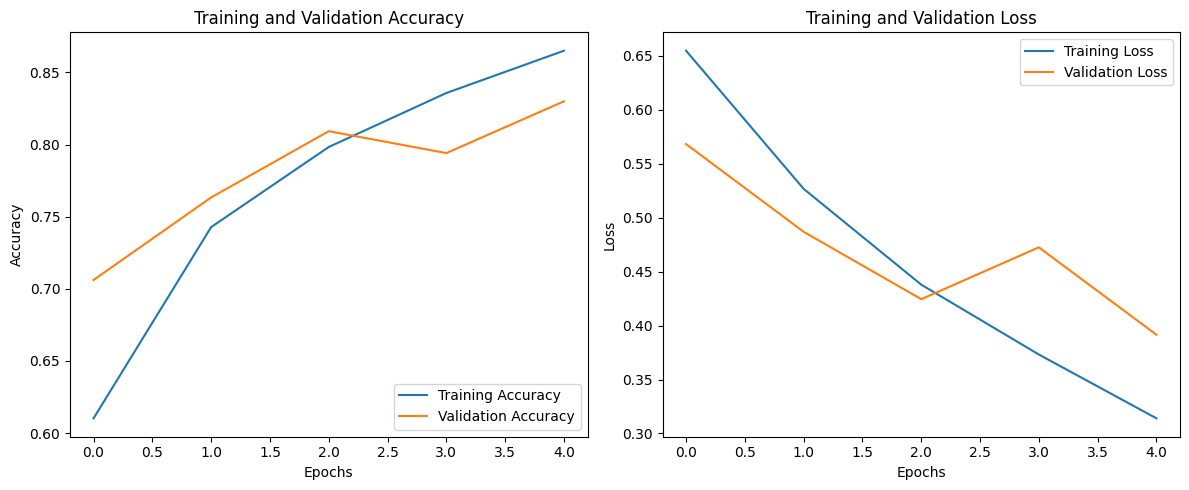

In [ ]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.tight_layout()
plt.show()